In [1]:
import torch
import torch.nn as nn
from torch.nn import functional as F

In [30]:
batch_size = 64
block_size = 256
device = 'cuda' if torch.cuda.is_available() else 'cpu'
eval_interval = 300
eval_iters = 200
max_iters = 5000
n_layer = 6
n_head = 6
learning_rate=3e-4
n_embd = 384
dropout = 0.2

In [4]:
with open("./input.txt") as f:
    text = f.read()

In [5]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(chars)
print(vocab_size)

['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']
65


In [6]:
stoi = { ch: i for i, ch in enumerate(chars)}
itos = { i: ch for i, ch in enumerate(chars)}
encode = lambda s: [stoi[c] for c in s]
decode = lambda l: "".join([itos[i] for i in l]) 

In [7]:
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9*len(data))
train_data = data[:n]
val_data = data[n:]

In [8]:
def get_batch(split):
    data = train_data if split == 'train' else val_data
    ix = torch.randint(len(data) - block_size, (batch_size, ))
    x = torch.stack([data[i:i+block_size] for i in ix])
    y = torch.stack([data[i+1:i+block_size+1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y

xb, yb = get_batch('train')
print(xb.shape)
print(xb[0], yb[0])

torch.Size([64, 256])
tensor([51, 53, 57, 58,  1, 54, 43, 43, 56, 50, 43, 57, 57,  1, 54, 47, 43, 41,
        43,  1, 53, 44,  1, 43, 39, 56, 58, 46,  6,  1, 21,  1, 58, 46, 47, 52,
        49,  6,  0, 32, 46, 39, 58,  1, 43,  5, 43, 56,  1, 58, 46, 43,  1, 57,
        59, 52,  1, 57, 46, 53, 52, 43,  1, 40, 56, 47, 45, 46, 58,  1, 53, 52,
         8,  0,  0, 28, 13, 33, 24, 21, 26, 13, 10,  0, 27,  1, 20, 43, 56, 51,
        47, 53, 52, 43,  6,  0, 13, 57,  1, 43, 60, 43, 56, 63,  1, 54, 56, 43,
        57, 43, 52, 58,  1, 58, 47, 51, 43,  1, 42, 53, 58, 46,  1, 40, 53, 39,
        57, 58,  1, 47, 58, 57, 43, 50, 44,  0, 13, 40, 53, 60, 43,  1, 39,  1,
        40, 43, 58, 58, 43, 56,  1, 45, 53, 52, 43,  6,  1, 57, 53,  1, 51, 59,
        57, 58,  1, 58, 46, 63,  1, 45, 56, 39, 60, 43,  0, 19, 47, 60, 43,  1,
        61, 39, 63,  1, 58, 53,  1, 61, 46, 39, 58,  5, 57,  1, 57, 43, 43, 52,
         1, 52, 53, 61,  2,  1, 31, 47, 56,  6,  1, 63, 53, 59,  1, 63, 53, 59,
        56, 57, 43

In [23]:
@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ['train', 'val']:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out

In [ ]:
class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, vocab_size)

    def forward(self, idx, targets=None):
        logits = self.token_embedding_table(idx)

        if targets is None:
            loss = None
        else:
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            logits, loss = self(idx)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)

        return idx

In [ ]:
model = BigramLanguageModel(vocab_size)
m = model.to(device)

In [ ]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=400)[0].tolist()))

In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

for iter in range(max_iters):
    if iter % eval_interval == 0:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    xb, yb = get_batch('train')

    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

In [ ]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(context, max_new_tokens=400)[0].tolist()))

In [45]:
# Visualize the token embedding table after training.
# Paste this at the bottom of bigram.py or gpt.py (after the training loop),
# then call:  plot_embedding_table(model, itos)

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F


def _label(ch):
    # make invisible characters readable on the axes
    return {'\n': '\\n', ' ': '␣', '\t': '\\t'}.get(ch, ch)


@torch.no_grad()
def plot_embedding_table(model, itos, save_prefix='embedding'):
    W = model.token_embedding_table.weight.detach().cpu().float()  # (vocab_size, channels)
    V, C = W.shape
    labels = [_label(itos[i]) for i in range(V)]
    ticks = range(V)

    # 1) The raw table: token x channels
    fig, ax = plt.subplots(figsize=(14, 6))
    lim = W.abs().max().item()
    im = ax.imshow(W, aspect='auto', cmap='RdBu_r', vmin=-lim, vmax=lim)
    ax.set_yticks(ticks, labels, fontsize=6)
    if C == V:
        # bigram: each column is a possible next character, so label it as one
        ax.set_xticks(ticks, labels, fontsize=6)
        ax.set_xlabel('next token')
        ax.set_ylabel('current token')
        ax.set_title(f'Bigram table: score for (current -> next)  ({V} x {V})')
    else:
        # gpt: columns are unnamed learned features
        ax.set_xlabel(f'channel (0..{C-1})')
        ax.set_ylabel('token')
        ax.set_title(f'Token embedding table  ({V} tokens x {C} channels)')
    fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(f'{save_prefix}_raw.png', dpi=150)

    # 2) Bigram model only: rows are next-token scores, so show them as probabilities
    if C == V:
        P = F.softmax(W, dim=1)  # each row sums to 1
        fig, ax = plt.subplots(figsize=(10, 10))
        im = ax.imshow(P, cmap='Blues')
        ax.set_xticks(ticks, labels, fontsize=6)
        ax.set_yticks(ticks, labels, fontsize=6)
        ax.set_xlabel('next token')
        ax.set_ylabel('current token')
        ax.set_title('Bigram: P(next | current)')
        fig.colorbar(im, ax=ax, fraction=0.046)
        fig.tight_layout()
        fig.savefig(f'{save_prefix}_bigram_probs.png', dpi=150)

    # 3) Token x token similarity, computed across the channels
    Wn = F.normalize(W, dim=1)
    S = Wn @ Wn.T  # (V, V) cosine similarity
    fig, ax = plt.subplots(figsize=(10, 10))
    im = ax.imshow(S, cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(ticks, labels, fontsize=6)
    ax.set_yticks(ticks, labels, fontsize=6)
    ax.set_title('Cosine similarity between token embeddings')
    fig.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(f'{save_prefix}_similarity.png', dpi=150)

    # 4) 2D map: squash the channels down to 2 with PCA, so similar tokens sit close together
    Wc = W - W.mean(dim=0)
    _, _, Vh = torch.linalg.svd(Wc, full_matrices=False)
    xy = Wc @ Vh[:2].T  # (V, 2)
    fig, ax = plt.subplots(figsize=(9, 9))
    ax.scatter(xy[:, 0], xy[:, 1], s=0)
    for i, lab in enumerate(labels):
        ch = itos[i]
        color = ('tab:red' if ch.lower() in 'aeiou' else
                 'tab:blue' if ch.isalpha() else
                 'tab:green' if ch.isdigit() else 'tab:gray')
        ax.text(xy[i, 0], xy[i, 1], lab, fontsize=11, ha='center', va='center', color=color)
    ax.set_xlabel('PC 1')
    ax.set_ylabel('PC 2')
    ax.set_title('Token embeddings projected to 2D (red = vowels, blue = consonants)')
    fig.tight_layout()
    fig.savefig(f'{save_prefix}_pca.png', dpi=150)

    plt.show()


# after training:
# plot_embedding_table(model, itos)

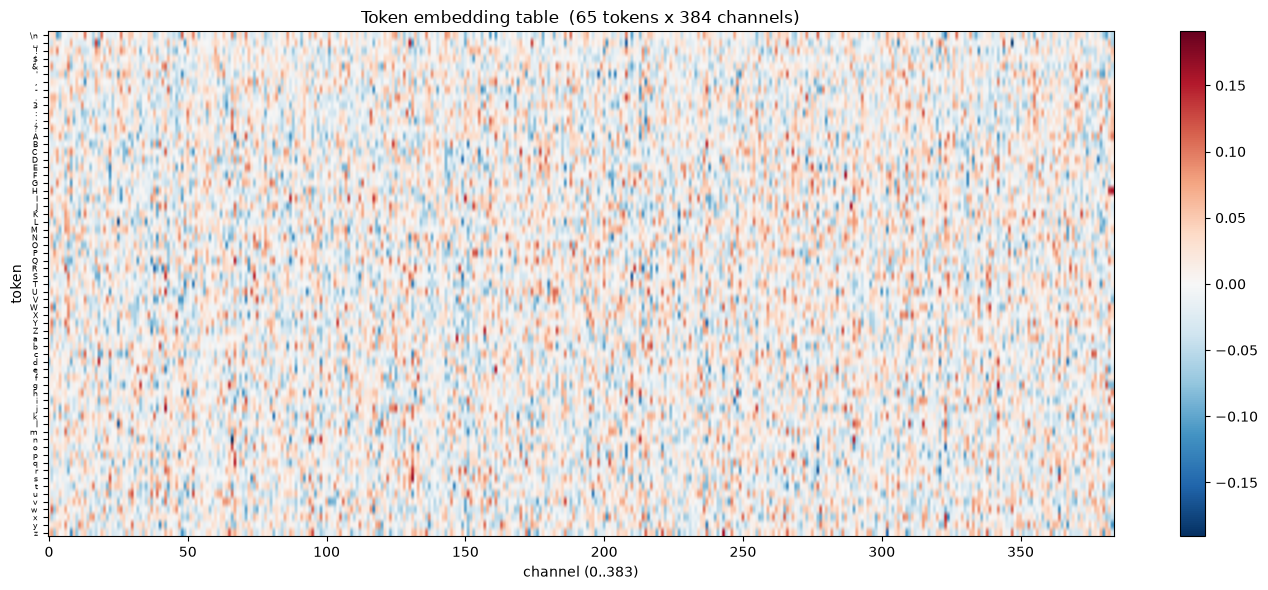

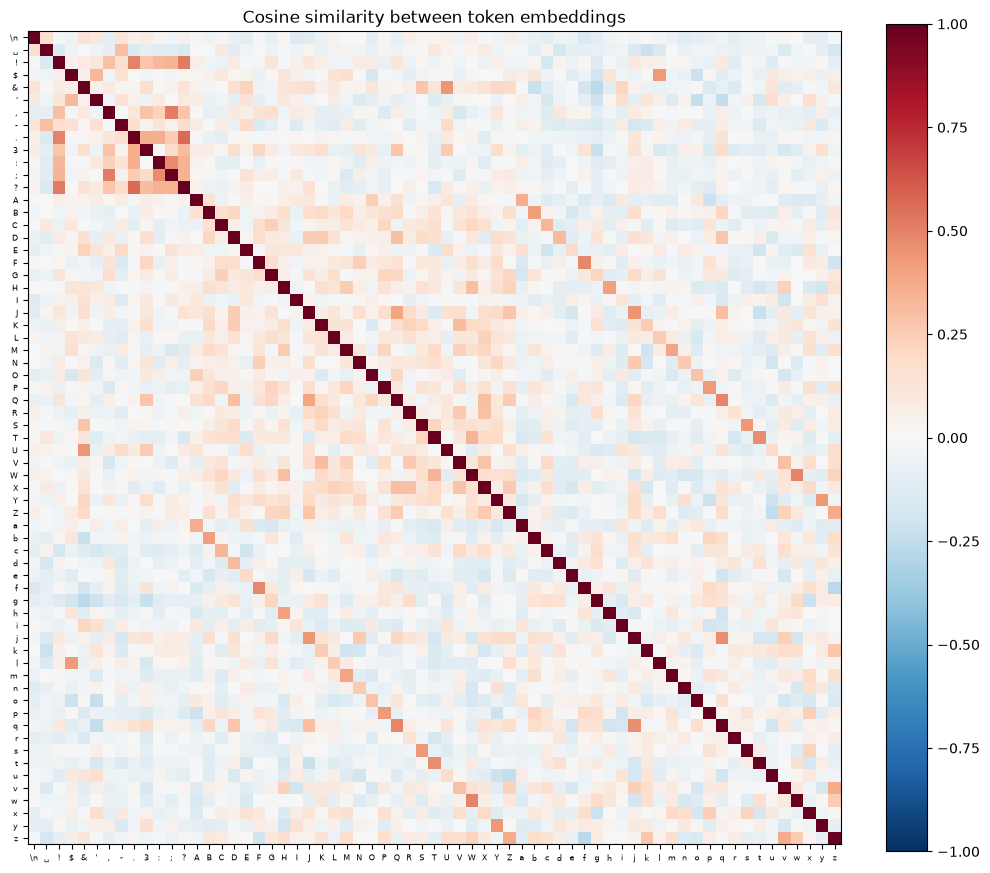

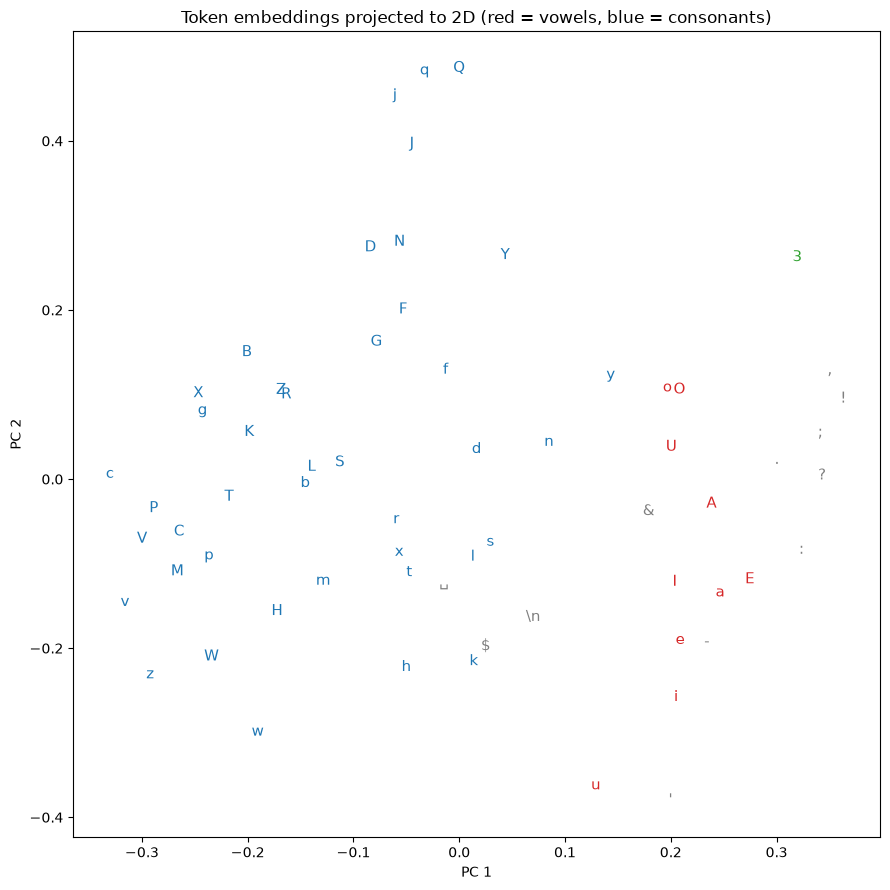

In [46]:
plot_embedding_table(model, itos)

# GPT Model

In [12]:

class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)

        self.register_buffer('tril', torch.tril(torch.ones(block_size, block_size)))

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)
        wei = q @ k.transpose(-2, -1) * k.shape[-1]**-0.5

        wei = wei.masked_fill(self.tril[:T, :T] == 0, float('-inf'))
        wei = F.softmax(wei, dim=-1)
        wei = self.dropout(wei)

        v = self.value(x)
        out = wei @ v
        return out

In [13]:
class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([Head(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(head_size * num_heads, n_embd)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out

In [14]:
class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)

In [15]:
class Block(nn.Module):
    def __init__(self, n_embed, n_head):
        super().__init__()
        head_size = n_embd // n_head
        self.sa = MultiHeadAttention(n_head, head_size)
        self.ffwd = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

In [27]:
class GPTLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.position_embedding_table = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size) # The output is 64 possiblities

        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        tok_emb = self.token_embedding_table(idx)
        pos_emb = self.position_embedding_table(torch.arange(T, device=device))
        x = tok_emb + pos_emb
        x = self.blocks(x)
        x = self.ln_f(x)
        logits = self.lm_head(x)

        if targets is None:
            loss = None
        else: 
            B,T,C = logits.shape
            logits = logits.view(B*T, C)
            targets = targets.view(B*T)
            loss = F.cross_entropy(logits, targets)

        return logits, loss

    def generate(self, idx, max_new_tokens):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -block_size:]
            logits, loss = self(idx_cond)
            logits = logits[:, -1, :]
            probs = F.softmax(logits, dim=-1)
            idx_next = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, idx_next), dim=1)

        return idx

In [28]:
model = GPTLanguageModel()
m = model.to(device)
print(sum(p.numel() for p in m.parameters())/1e6, 'M parameters')

10.788929 M parameters


In [31]:
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

for iter in range(max_iters):
    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}")

    xb, yb = get_batch('train')

    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step 0: train loss 2.2748, val loss 2.3257
step 300: train loss 1.7363, val loss 1.8913
step 600: train loss 1.4873, val loss 1.6988
step 900: train loss 1.3693, val loss 1.5907
step 1200: train loss 1.2872, val loss 1.5389
step 1500: train loss 1.2320, val loss 1.5108
step 1800: train loss 1.1898, val loss 1.5016
step 2100: train loss 1.1537, val loss 1.4939
step 2400: train loss 1.1165, val loss 1.4824
step 2700: train loss 1.0817, val loss 1.4771
step 3000: train loss 1.0513, val loss 1.4927
step 3300: train loss 1.0172, val loss 1.4905
step 3600: train loss 0.9877, val loss 1.5054
step 3900: train loss 0.9547, val loss 1.5119
step 4200: train loss 0.9277, val loss 1.5251
step 4500: train loss 0.8951, val loss 1.5394
step 4800: train loss 0.8661, val loss 1.5572
step 4999: train loss 0.8461, val loss 1.5709


In [47]:
context = torch.zeros((1, 1), dtype=torch.long, device=device)
print(decode(m.generate(torch.tensor([[12]], device=device), max_new_tokens=500)[0].tolist()))

?
How now! what's this? Marcius Lartius? would he that?
Either o of our silent groans! wretched Clarence!
What king's bound and how shall we speak for our country?

ROMEO:
But for the night of the death, I fear thee,
Thou hast told thee, and I must do we hear
The heavens of this use that hopes he bleeds
Not applied after?

FLORIZEL:
Bless
Are you me
Stirr'd to the city faults: what lies
The unrest o' the stroke of fee-month? I have made you
Have been benefit by the fatal to ear
A master of times,


In [50]:
print(model.state_dict())
torch.save(model.state_dict(), './shakespear.pt')
model.eval()

OrderedDict({'token_embedding_table.weight': tensor([[ 0.0107,  0.0247,  0.0358,  ..., -0.1020, -0.0307, -0.0535],
        [-0.0255, -0.0395,  0.0320,  ..., -0.0296,  0.0650, -0.0635],
        [ 0.0371,  0.0556,  0.0241,  ...,  0.0246,  0.0183,  0.0584],
        ...,
        [ 0.0529, -0.0567, -0.0313,  ..., -0.0696, -0.0569, -0.0460],
        [ 0.0033,  0.0198,  0.0340,  ...,  0.0640, -0.0384, -0.1147],
        [ 0.0521,  0.0749, -0.0690,  ...,  0.0495,  0.0630, -0.0303]],
       device='cuda:0'), 'position_embedding_table.weight': tensor([[-0.2039, -0.0150,  0.0171,  ...,  0.0237,  0.0610,  0.0202],
        [-0.0524,  0.0768,  0.0412,  ..., -0.0490, -0.0269,  0.0071],
        [-0.1066,  0.0665,  0.0437,  ..., -0.0048, -0.0426,  0.0298],
        ...,
        [ 0.0471, -0.0301,  0.0230,  ..., -0.0067,  0.0069, -0.0094],
        [ 0.0400, -0.0018,  0.0311,  ...,  0.0025,  0.0111,  0.0085],
        [ 0.0746,  0.0609, -0.0133,  ..., -0.0184, -0.0137,  0.0281]],
       device='cuda:0'), 'b

GPTLanguageModel(
  (token_embedding_table): Embedding(65, 384)
  (position_embedding_table): Embedding(256, 384)
  (blocks): Sequential(
    (0): Block(
      (sa): MultiHeadAttention(
        (heads): ModuleList(
          (0-5): 6 x Head(
            (key): Linear(in_features=384, out_features=64, bias=False)
            (query): Linear(in_features=384, out_features=64, bias=False)
            (value): Linear(in_features=384, out_features=64, bias=False)
            (dropout): Dropout(p=0.2, inplace=False)
          )
        )
        (proj): Linear(in_features=384, out_features=384, bias=True)
        (dropout): Dropout(p=0.2, inplace=False)
      )
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=384, out_features=1536, bias=True)
          (1): ReLU()
          (2): Linear(in_features=1536, out_features=384, bias=True)
          (3): Dropout(p=0.2, inplace=False)
        )
      )
      (ln1): LayerNorm((384,), eps=1e-05, elementwise_affine

In [49]:
print(torch.tril(torch.ones(block_size, block_size)))

tensor([[1., 0., 0.,  ..., 0., 0., 0.],
        [1., 1., 0.,  ..., 0., 0., 0.],
        [1., 1., 1.,  ..., 0., 0., 0.],
        ...,
        [1., 1., 1.,  ..., 1., 0., 0.],
        [1., 1., 1.,  ..., 1., 1., 0.],
        [1., 1., 1.,  ..., 1., 1., 1.]])


In [ ]:
B,T,C = 4,8,32
x = torch.randn(B,T,C)

print(x.shape)

key = nn.Linear(C, 16, bias=False)
query = nn.Linear(C, 16, bias=False)

k = key(x)
q = query(x)

print(k.shape)
wei = q @ k.transpose(-2, -1)

tril = torch.tril(torch.ones(T,T))
wei = wei.masked_fill(tril==0, float('-inf'))
wei = F.softmax(wei, dim=-1)

print(wei[0])

In [8]:
import tiktoken
enc = tiktoken.get_encoding("o200k_base")
print(enc.encode("Hello, how are you?"))

[13225, 11, 1495, 553, 481, 30]
